# Exploración de los datos del petróleo

Este cuaderno revisa el dataset del caso práctico antes de entrenar RNN, LSTM y GRU.
La variable objetivo es el **precio spot del Brent, en dólares por barril**.
Buscamos entender la cobertura, los huecos, los cambios bruscos y cómo separar las fechas.

**Alcance:** análisis descriptivo y propuesta de preparación. No se entrenan modelos ni se mide su rendimiento.
Las vistas del histórico completo sirven para auditar los datos; las correlaciones se calculan solo en entrenamiento.
El periodo de prueba quedará reservado para evaluar los modelos una vez fijado el procedimiento.

Fuentes: [material oficial](https://github.com/UAX-VCMT-26-27/aa-case-02-oil-price-prediction),
[Brent en FRED](https://fred.stlouisfed.org/series/DCOILBRENTEU),
[WTI en FRED](https://fred.stlouisfed.org/series/DCOILWTICO) y Yahoo Finance mediante el script de la asignatura.
Se trabaja sobre la copia local: ejecutar este cuaderno no descarga ni modifica el CSV.

In [1]:
from pathlib import Path
from hashlib import sha256
from importlib.metadata import version
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "data/petroleo_dataset.csv").exists())
DATA = ROOT / "data/petroleo_dataset.csv"
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (11, 4.8), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .18, "font.size": 10})
BLUE, ORANGE, GREEN = "#176B98", "#C66A26", "#34806D"

def guardar_figura(fig, nombre):
    fig.savefig(FIGURES / nombre, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

df = pd.read_csv(DATA, parse_dates=["Date"]).set_index("Date")
assert not df.empty and "brent" in df
assert df.index.is_monotonic_increasing, "Revisar orden de las fechas"
assert df.index.is_unique, "Revisar fechas duplicadas"
assert df.index.notna().all(), "Hay fechas inválidas"
assert df.select_dtypes(include="number").shape[1] == df.shape[1]
assert np.isfinite(df.to_numpy(dtype=float)[df.notna().to_numpy()]).all()
assert df["brent"].notna().all(), "Falta la variable objetivo"

huella = sha256(DATA.read_bytes()).hexdigest()
display(Markdown(f"**Copia analizada:** {len(df):,} filas y {df.shape[1]} variables, "
                 f"del {df.index.min():%d/%m/%Y} al {df.index.max():%d/%m/%Y}."))
print("SHA-256 del CSV:", huella)
print("Python:", sys.version.split()[0])
print({p: version(p) for p in ["pandas", "numpy", "matplotlib"]})
display(df.head())

**Copia analizada:** 7,003 filas y 20 variables, del 04/01/2000 al 05/11/2026.

SHA-256 del CSV: 859aad2bc3ed770727893542774c371aa428beff26b1d7f8bc0a015331f19011
Python: 3.12.6
{'pandas': '3.1.0', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}


,brent,wti,gas_natural,tipo_bce,usd_por_eur,cny_por_usd,vix,brent_fut_Open,brent_fut_High,brent_fut_Low,brent_fut_Close,brent_fut_Volume,wti_fut_Open,wti_fut_High,wti_fut_Low,wti_fut_Close,wti_fut_Volume,indice_dolar,oro,cobre
Date,,,,,,,,,,,,,,,,,,,,
2000-01-04,23.95,25.56,NaN,2.0,1.0309,8.2799,27.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.410004,NaN,NaN
2000-01-05,23.72,24.65,NaN,2.0,1.0335,8.2798,26.41,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.379997,NaN,NaN
2000-01-06,23.55,24.79,NaN,2.0,1.0324,8.2797,25.73,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.650002,NaN,NaN
2000-01-07,23.35,24.79,NaN,2.0,1.0294,8.2794,21.72,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.800003,NaN,NaN
2000-01-10,22.77,24.71,2.2,2.0,1.0252,8.2794,21.71,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.989998,NaN,NaN


## 1. Qué contiene cada variable

El script reúne series de distintas fuentes y unidades. No se deben comparar sus magnitudes directamente.
Los futuros y el precio spot representan instrumentos distintos. El volumen no es un precio.

| Grupo | Columnas | Unidad / fuente |
|---|---|---|
| Precio objetivo | `brent` | USD/barril; FRED, DCOILBRENTEU |
| Otra referencia spot | `wti` | USD/barril; FRED, DCOILWTICO |
| Gas natural | `gas_natural` | USD por millón de BTU; FRED, DHHNGSP |
| Tipo del BCE | `tipo_bce` | Porcentaje; FRED, ECBDFR |
| Divisas | `usd_por_eur`, `cny_por_usd` | USD/EUR y CNY/USD; FRED |
| Volatilidad | `vix` | Puntos de índice; FRED, VIXCLS |
| Futuros de petróleo | `brent_fut_*`, `wti_fut_*` | OHLC en USD/barril y volumen de contratos; Yahoo, BZ=F y CL=F |
| Otros mercados | `indice_dolar`, `oro`, `cobre` | Puntos, USD/onza troy y USD/libra; Yahoo, DX-Y.NYB, GC=F y HG=F |

La cesta OPEP mencionada en el enunciado **no está incluida** en este CSV.
La disponibilidad histórica no garantiza que un valor se publicara el mismo día al que se refiere.
Antes de un backtest realista habrá que aplicar los retrasos de publicación y definir a qué hora se emite la predicción.

## 2. Cobertura y valores faltantes

El script oficial ordena las series, aplica `ffill()` y elimina los fines de semana.
Por eso el CSV ya contiene valores propagados y no permite reconstruir todos los huecos originales.
Un porcentaje bajo de nulos no demuestra que haya cotización nueva todos los días.

Los huecos anteriores al inicio de una serie no se rellenan con `ffill()`.
No usaremos `bfill()` ni interpolación con valores posteriores: introducirían información futura.

,primera_fecha,ultima_fecha_no_nula,nulos,nulos_pct,repeticiones_consecutivas
brent,2000-01-04,2026-11-05,0,0.00,572
wti,2000-01-04,2026-11-05,0,0.00,687
gas_natural,2000-01-10,2026-11-05,4,0.06,2109
tipo_bce,2000-01-04,2026-11-05,0,0.00,6943
usd_por_eur,2000-01-04,2026-11-05,0,0.00,336
cny_por_usd,2000-01-04,2026-11-05,0,0.00,1107
vix,2000-01-04,2026-11-05,0,0.00,254
brent_fut_Open,2007-07-30,2026-11-05,1974,28.19,251
brent_fut_High,2007-07-30,2026-11-05,1974,28.19,257
brent_fut_Low,2007-07-30,2026-11-05,1974,28.19,257


Faltan **0** fechas del calendario lunes-viernes. El Brent repite el precio anterior en **572** filas. Estas repeticiones pueden ser precios iguales o valores propagados; no se pueden separar con este CSV.

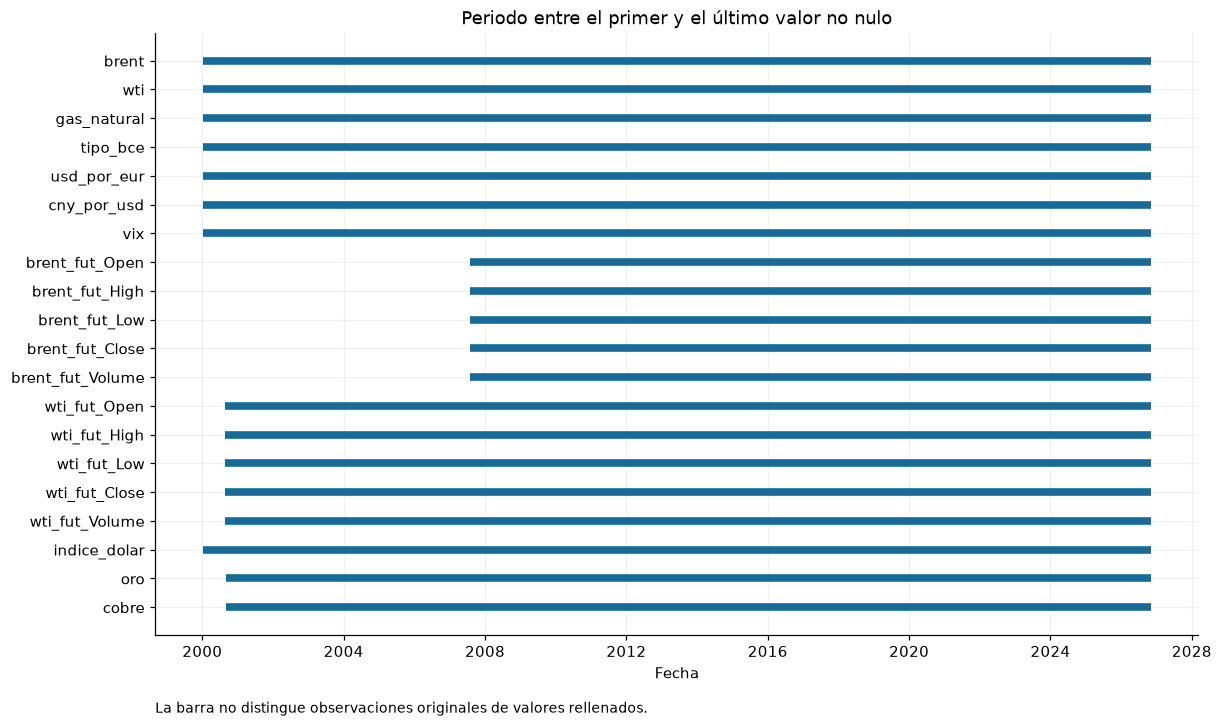

In [2]:
cobertura = pd.DataFrame({
    "primera_fecha": df.apply(lambda s: s.first_valid_index()),
    "ultima_fecha_no_nula": df.apply(lambda s: s.last_valid_index()),
    "nulos": df.isna().sum(),
    "nulos_pct": df.isna().mean().mul(100).round(2),
    "repeticiones_consecutivas": df.eq(df.shift(1)).sum(),
})
display(cobertura)

calendario = pd.bdate_range(df.index.min(), df.index.max())
faltan_laborables = calendario.difference(df.index)
display(Markdown(f"Faltan **{len(faltan_laborables)}** fechas del calendario lunes-viernes. "
                 f"El Brent repite el precio anterior en **{df.brent.eq(df.brent.shift()).sum()}** filas. "
                 "Estas repeticiones pueden ser precios iguales o valores propagados; no se pueden separar con este CSV."))

fig, ax = plt.subplots(figsize=(11, 6.5), layout="constrained")
posiciones = np.arange(len(df.columns))
for i, nombre in enumerate(df.columns):
    inicio = df[nombre].first_valid_index()
    fin = df[nombre].last_valid_index()
    if inicio is not None:
        ax.plot([inicio, fin], [i, i], color=BLUE, linewidth=5, solid_capstyle="butt")
ax.set_yticks(posiciones, df.columns)
ax.invert_yaxis()
ax.set(title="Periodo entre el primer y el último valor no nulo", xlabel="Fecha")
ax.text(0, -0.13, "La barra no distingue observaciones originales de valores rellenados.", transform=ax.transAxes, fontsize=9)
guardar_figura(fig, "01_cobertura.png")

## 3. Evolución del Brent y del WTI

Los precios se muestran en la misma unidad. Las líneas verticales señalan periodos que el enunciado
pide estudiar; por sí solas no prueban una relación causal. El tramo reciente se describe sin atribuirle una causa no verificada.

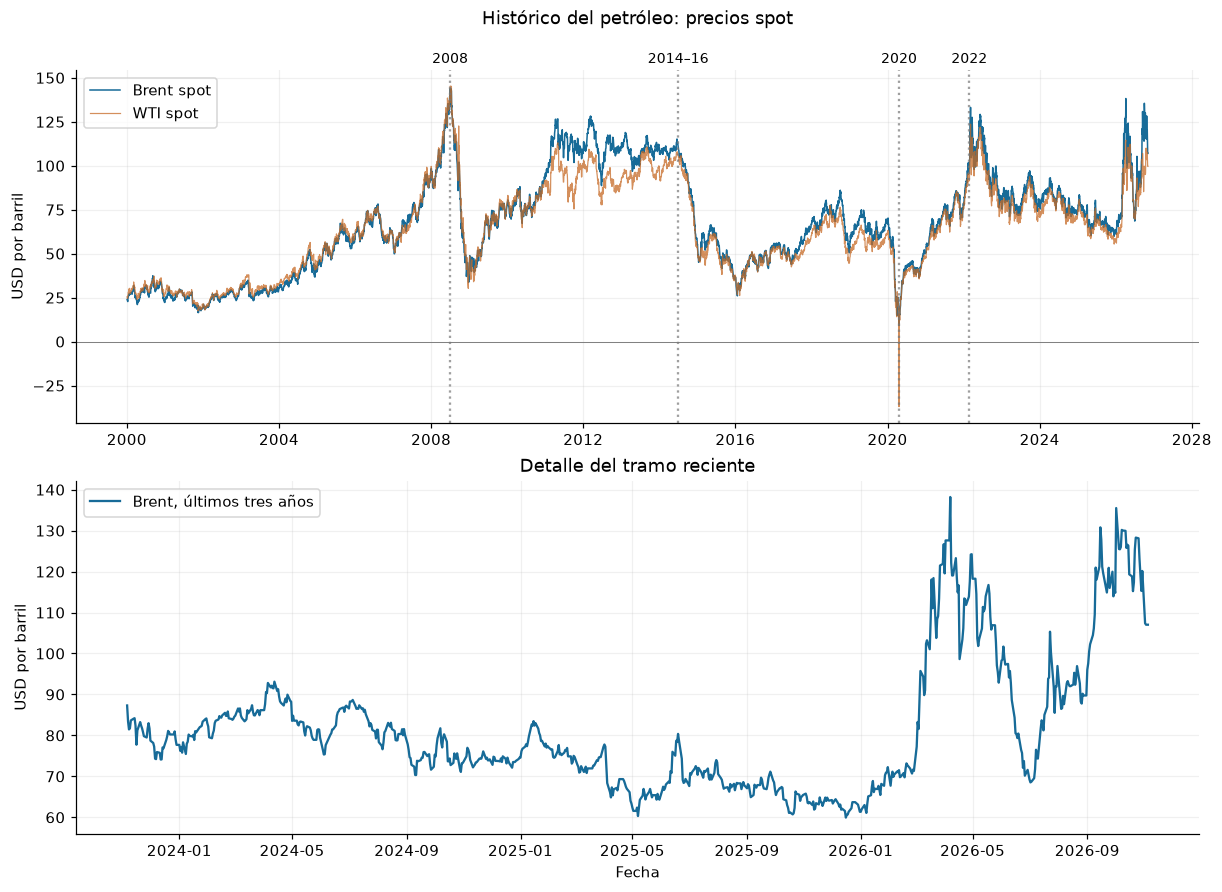

,minimo,fecha_minimo,maximo,fecha_maximo
brent,9.12,2020-04-21,143.95,2008-07-03
wti,-36.98,2020-04-20,145.31,2008-07-03


,brent,wti,wti_fut_Close
Date,,,
2020-04-20,17.36,-36.98,-37.630001


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), layout="constrained")
axes[0].plot(df.index, df.brent, label="Brent spot", color=BLUE, linewidth=1)
axes[0].plot(df.index, df.wti, label="WTI spot", color=ORANGE, linewidth=.8, alpha=.75)
for fecha, etiqueta in [("2008-07-01", "2008"), ("2014-07-01", "2014–16"),
                        ("2020-04-20", "2020"), ("2022-02-24", "2022")]:
    axes[0].axvline(pd.Timestamp(fecha), color="#777777", linestyle=":", alpha=.7)
    axes[0].text(pd.Timestamp(fecha), 1.02, etiqueta,
                 transform=axes[0].get_xaxis_transform(), fontsize=9, ha="center")
axes[0].axhline(0, color="#777777", linewidth=.6)
axes[0].set(ylabel="USD por barril")
axes[0].set_title("Histórico del petróleo: precios spot", pad=30)
axes[0].legend(loc="upper left")
reciente = df.loc[df.index.max() - pd.DateOffset(years=3):]
axes[1].plot(reciente.index, reciente.brent, color=BLUE, label="Brent, últimos tres años")
axes[1].set(title="Detalle del tramo reciente", ylabel="USD por barril", xlabel="Fecha")
axes[1].legend()
guardar_figura(fig, "02_historico.png")

extremos = pd.DataFrame({
    "minimo": df[["brent", "wti"]].min(),
    "fecha_minimo": df[["brent", "wti"]].idxmin(),
    "maximo": df[["brent", "wti"]].max(),
    "fecha_maximo": df[["brent", "wti"]].idxmax(),
})
display(extremos)
display(df.loc[df.wti.lt(0), ["brent", "wti", "wti_fut_Close"]])

**Interpretación:** los episodios extremos se conservan para su estudio. Un valor negativo del WTI no
se elimina automáticamente como error. El precio spot `wti` y el cierre del futuro `wti_fut_Close` pueden
ser diferentes incluso en la misma fecha; no hay que sustituir uno por otro.

El enunciado relaciona 2008 con la crisis financiera, 2014–2016 con exceso de oferta,
2020 con la pandemia y 2022 con la invasión de Ucrania. Es contexto para interpretar el histórico,
no una explicación causal estimada por este cuaderno.

## 4. Cambios diarios y volatilidad

Para el Brent calculamos el cambio porcentual entre filas consecutivas y su desviación estándar móvil
de 63 filas, mirando solo al pasado. No es volatilidad anualizada ni un intervalo de predicción.
El relleno de días sin cotización puede generar cambios cero y alterar estas medidas.
No calculamos rentabilidades logarítmicas del WTI porque contiene precios negativos.

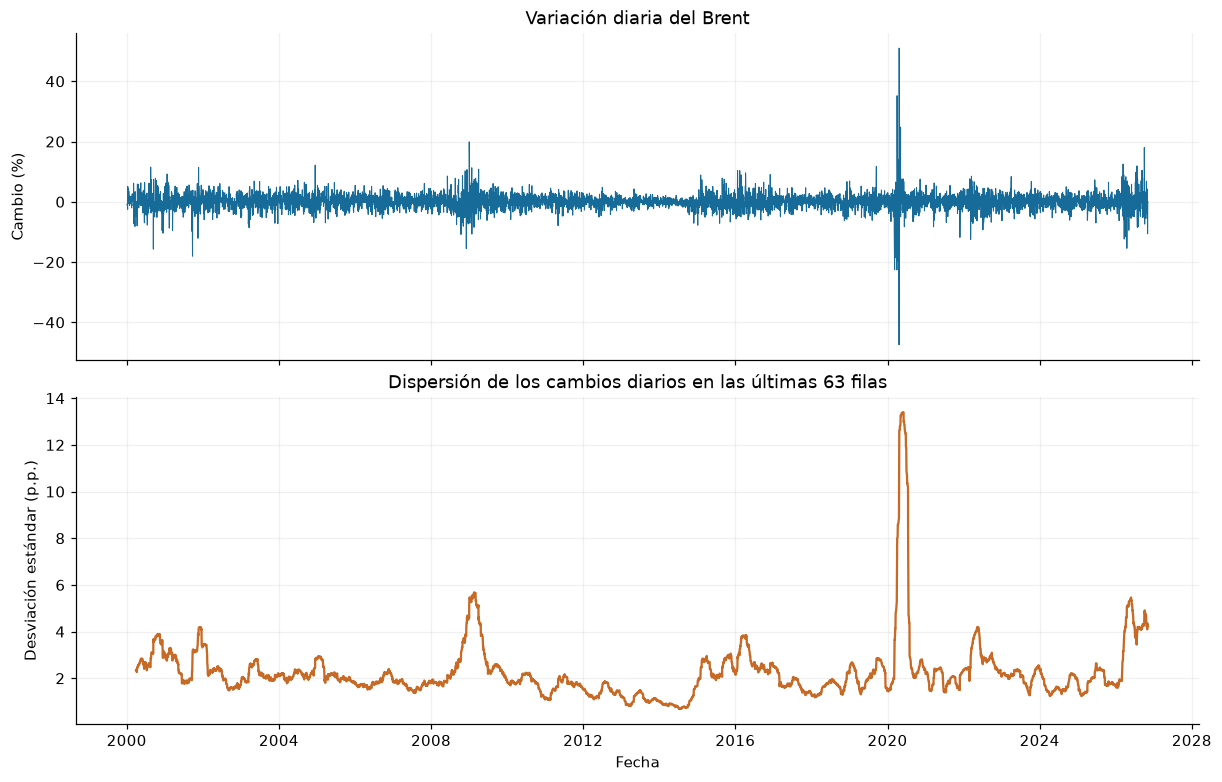

,brent,cambio_usd,cambio_pct
Date,,,
2009-01-02,42.94,7.12,19.877
2020-03-09,35.33,-10.27,-22.522
2020-03-18,22.79,-5.18,-18.520
2020-03-31,14.85,-4.34,-22.616
2020-04-02,20.24,5.27,35.204
2020-04-03,24.33,4.09,20.208
2020-04-09,20.23,-4.99,-19.786
2020-04-21,9.12,-8.24,-47.465
2020-04-22,13.77,4.65,50.987


In [4]:
retorno = df.brent.pct_change(fill_method=None).mul(100)
volatilidad = retorno.rolling(63, min_periods=63).std()
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, layout="constrained")
axes[0].plot(retorno.index, retorno, color=BLUE, linewidth=.7)
axes[0].set(title="Variación diaria del Brent", ylabel="Cambio (%)")
axes[1].plot(volatilidad.index, volatilidad, color=ORANGE)
axes[1].set(title="Dispersión de los cambios diarios en las últimas 63 filas",
            ylabel="Desviación estándar (p.p.)", xlabel="Fecha")
guardar_figura(fig, "03_variaciones.png")

movimientos = pd.DataFrame({"brent": df.brent, "cambio_usd": df.brent.diff(), "cambio_pct": retorno})
display(movimientos.loc[retorno.abs().nlargest(10).index].sort_index().round(3))

## 5. Propuesta de separación temporal

Propuesta inicial por número de filas: **70 % entrenamiento, 15 % validación y 15 % prueba**, sin barajar.
Se fija antes de buscar hiperparámetros. No se seleccionará un modelo con resultados de prueba.
Los límites se obtienen de esta copia; si se actualizan los datos, habrá que congelar las fechas del experimento.

Para predecir a 5, 63 o 252 pasos, una muestra pertenece a un bloque únicamente si tanto la fecha
de origen como la fecha del objetivo quedan dentro de ese bloque. Se descartan al final de cada bloque
los orígenes cuyo objetivo cae en el siguiente. Las ventanas de validación o prueba sí pueden usar
historia anterior al inicio del bloque, porque esa información ya existía en el momento de predecir.

,inicio,fin,filas
bloque,,,
Entrenamiento,2000-01-04,2018-10-17,4902
Validación,2018-10-18,2022-10-26,1050
Prueba,2022-10-27,2026-11-05,1051


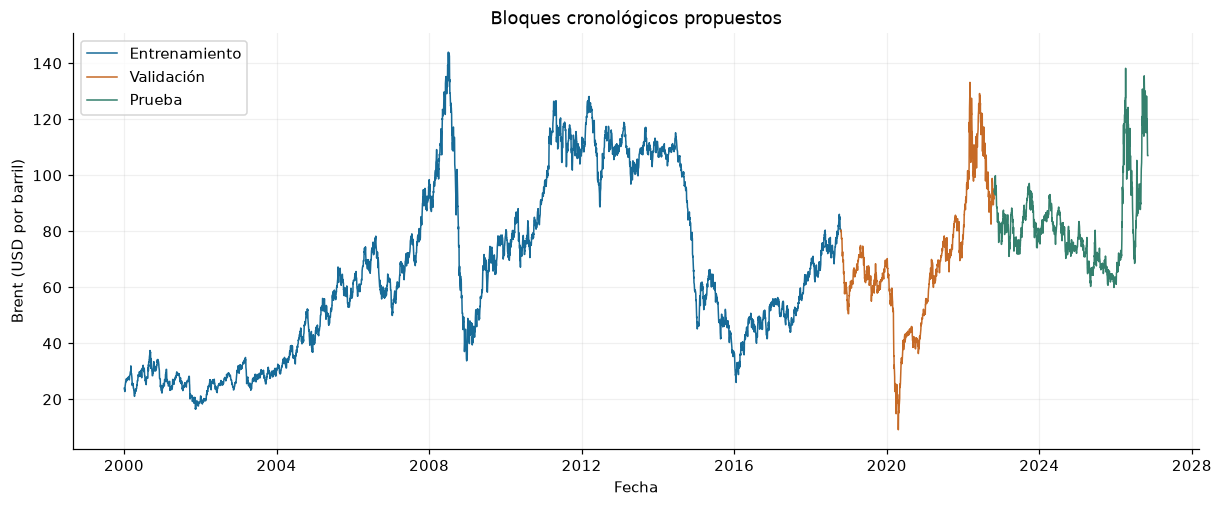

bloque,Entrenamiento,Prueba,Validación
horizonte_filas,,,
5,4838,1046,1045
63,4780,988,987
252,4591,799,798


In [5]:
n = len(df)
corte_train, corte_val = int(n * .70), int(n * .85)
bloques = {"Entrenamiento": (0, corte_train), "Validación": (corte_train, corte_val), "Prueba": (corte_val, n)}
train = df.iloc[:corte_train].copy()
particion = pd.DataFrame([
    {"bloque": nombre, "inicio": df.index[a], "fin": df.index[b - 1], "filas": b - a}
    for nombre, (a, b) in bloques.items()
]).set_index("bloque")
display(particion)
assert particion.loc["Entrenamiento", "fin"] < particion.loc["Validación", "inicio"]
assert particion.loc["Validación", "fin"] < particion.loc["Prueba", "inicio"]

fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
for (nombre, (a, b)), color in zip(bloques.items(), [BLUE, ORANGE, GREEN]):
    ax.plot(df.index[a:b], df.brent.iloc[a:b], color=color, linewidth=1, label=nombre)
ax.set(title="Bloques cronológicos propuestos", ylabel="Brent (USD por barril)", xlabel="Fecha")
ax.legend()
guardar_figura(fig, "04_particion.png")

ventana = 60
conteos = []
for horizonte in [5, 63, 252]:
    for nombre, (a, b) in bloques.items():
        origenes = np.arange(max(a, ventana - 1), max(max(a, ventana - 1), b - horizonte))
        destinos = origenes + horizonte
        assert (destinos < b).all() and (origenes >= a).all()
        assert (origenes - ventana + 1 >= 0).all()
        conteos.append({"horizonte_filas": horizonte, "bloque": nombre,
                        "muestras_univariantes": len(origenes)})
display(pd.DataFrame(conteos).pivot(index="horizonte_filas", columns="bloque", values="muestras_univariantes"))

Estos conteos usan únicamente el Brent y una ventana de 60 filas, incluida la fecha de origen.
No son aún el conjunto de entrenamiento definitivo: los retrasos de publicación y las variables adicionales
pueden reducir las muestras disponibles. Un objetivo a 252 pasos es el precio al final de ese horizonte,
no una trayectoria completa de 252 predicciones.

El índice actual cubre lunes a viernes, incluidos festivos con valores rellenados.
Por tanto, **5, 63 y 252 filas no equivalen necesariamente a sesiones reales de cotización**.
Antes del entrenamiento se debe decidir y documentar el calendario usando las observaciones originales del Brent.
En la validación walk-forward se aplicará la misma exclusión de objetivos que cruzan el límite de cada fold.

## 6. Relaciones entre variables, solo en entrenamiento

Calculamos correlaciones de Pearson entre **cambios diarios en las unidades originales**, no entre niveles.
Esto reduce el efecto de tendencias comunes, aunque no demuestra causalidad ni capacidad predictiva.
Son correlaciones del mismo día; no justifican usar información que no estuviera publicada al predecir.

La matriz usa fechas comunes con todos los cambios disponibles para que cada celda tenga la misma muestra.
Esta eliminación de nulos es exclusivamente para la tabla exploratoria, no un método de preparación del modelo.

Muestra común: **4,730** fechas, del 31/08/2000 al 17/10/2018.

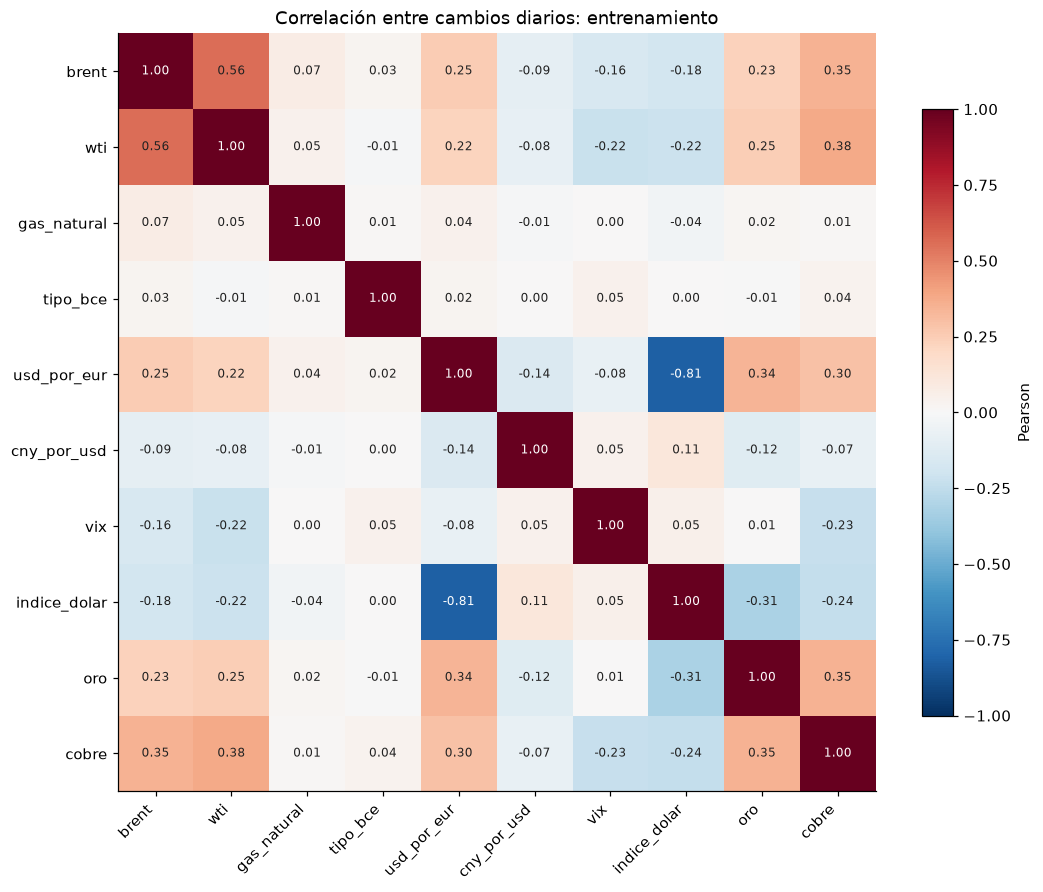

,correlacion_con_cambio_brent
wti,0.560458
cobre,0.348684
usd_por_eur,0.252687
oro,0.230898
gas_natural,0.070522
tipo_bce,0.031091
cny_por_usd,-0.087433
vix,-0.158165
indice_dolar,-0.184223


In [6]:
columnas = ["brent", "wti", "gas_natural", "tipo_bce", "usd_por_eur", "cny_por_usd", "vix", "indice_dolar", "oro", "cobre"]
cambios_train = train[columnas].diff().dropna()
correlacion = cambios_train.corr()
display(Markdown(f"Muestra común: **{len(cambios_train):,}** fechas, "
                 f"del {cambios_train.index.min():%d/%m/%Y} al {cambios_train.index.max():%d/%m/%Y}."))
fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
im = ax.imshow(correlacion, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(columnas)), columnas, rotation=45, ha="right")
ax.set_yticks(range(len(columnas)), columnas)
ax.grid(False)
for i in range(len(columnas)):
    for j in range(len(columnas)):
        v = correlacion.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > .6 else "#222222")
ax.set_title("Correlación entre cambios diarios: entrenamiento")
fig.colorbar(im, ax=ax, shrink=.8, label="Pearson")
guardar_figura(fig, "05_correlaciones.png")
display(correlacion["brent"].drop("brent").sort_values(ascending=False).to_frame("correlacion_con_cambio_brent"))

## 7. Decisiones para la siguiente fase

1. **Conservar la copia original y su huella.** Guardar observaciones sin rellenar y marcas de publicación
   al mejorar la descarga. No se puede recuperar esa información con certeza a partir del CSV actual.
2. **Definir el instante de predicción y el calendario.** Alinear las sesiones del Brent y retrasar las
   variables según su disponibilidad real. Evitar tratar un cierre de otro mercado como disponible antes de publicarse.
3. **Empezar por una comparación univariante.** RNN, LSTM, GRU y referencia ingenua usarán las mismas
   ventanas, fechas y horizontes. Después se podrá comparar una variante multivariante con presupuesto equivalente.
4. **Tratar huecos por variable.** No rellenar hacia atrás ni sustituir nulos por cero. Al incorporar futuros
   del Brent se acorta el periodo disponible a partir de 2007. No recortar todas las series sin explicar este coste.
5. **Conservar episodios extremos verificados.** No eliminar crisis por una regla global de outliers.
   Si se prueba una transformación robusta, sus parámetros se ajustan únicamente en entrenamiento.
6. **Escalar después de dividir.** Ajustar el escalador en cada fold de entrenamiento y aplicarlo sin reajuste
   a validación y prueba. No hay ningún escalador ajustado en este cuaderno.
7. **Medir contra la persistencia.** El modelo ingenuo predice el precio de origen para cada horizonte.
   Se compararán MSE, MAE y RMSE en USD/barril, además del coste de entrenamiento y la incertidumbre.
   No se dará por supuesto que una red mejora esa referencia.

La siguiente entrega técnica será la preparación reproducible de ventanas y la evaluación del modelo ingenuo.

In [7]:
display(Markdown(f"""
### Resumen de esta copia

- {len(df):,} filas y {df.shape[1]} variables, con fechas ordenadas y sin duplicados.
- Brent entre {df.brent.min():.2f} y {df.brent.max():.2f} USD/barril.
- Futuros del Brent disponibles desde {df.brent_fut_Close.first_valid_index():%d/%m/%Y}.
- {df.brent.eq(df.brent.shift()).sum()} repeticiones consecutivas del Brent; su origen no se puede distinguir en el CSV rellenado.
- Propuesta de prueba desde {particion.loc['Prueba', 'inicio']:%d/%m/%Y}; aún no hay modelos entrenados ni métricas de predicción.
"""))


### Resumen de esta copia

- 7,003 filas y 20 variables, con fechas ordenadas y sin duplicados.
- Brent entre 9.12 y 143.95 USD/barril.
- Futuros del Brent disponibles desde 30/07/2007.
- 572 repeticiones consecutivas del Brent; su origen no se puede distinguir en el CSV rellenado.
- Propuesta de prueba desde 27/10/2022; aún no hay modelos entrenados ni métricas de predicción.
